In [1]:
library(ggplot2)
library(data.table)
library(dplyr)
library(data.table)
library(stringr)

Warning message:
“程辑包‘ggplot2’是用R版本4.1.3 来建造的”

载入程辑包：‘dplyr’


The following objects are masked from ‘package:data.table’:

    between, first, last


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




# eQTL meta results

In [2]:
gg.manhattan <- function(
    df, threshold, sig, sugg, hlight,
    col, ylims, title, s_col,
    genome = "hg38"
){

    options(repr.plot.width = 20, repr.plot.height = 4)

    library(dplyr)
    library(ggplot2)

    #--------------------------------------------------
    # 1. Chromosome lengths
    #--------------------------------------------------
    if (genome == "hg38") {

        chr_len <- c(
            248956422, 242193529, 198295559, 190214555,
            181538259, 170805979, 159345973, 145138636,
            138394717, 133797422, 135086622, 133275309,
            114364328, 107043718, 101991189, 90338345,
            83257441, 80373285, 58617616, 64444167,
            46709983, 50818468
        )

    } else if (genome == "hg19") {

        chr_len <- c(
            249250621, 243199373, 198022430, 191154276,
            180915260, 171115067, 159138663, 146364022,
            141213431, 135534747, 135006516, 133851895,
            115169878, 107349540, 102531392, 90354753,
            81195210, 78077248, 59128983, 63025520,
            48129895, 51304566
        )

    } else {
        stop("genome must be either 'hg38' or 'hg19'")
    }


    #--------------------------------------------------
    # 2. Construct the complete chromosome 1-22 framework
    #--------------------------------------------------
    chr_info <- data.frame(
        chr = 1:22,
        chr_len = chr_len
    ) %>%
        mutate(
            tot = cumsum(chr_len) - chr_len,
            start = tot,
            end = tot + chr_len,
            center = tot + chr_len / 2
        )


    #--------------------------------------------------
    # 3. Prepare input data
    #--------------------------------------------------
    df.tmp <- df %>%

        mutate(
            chr = as.numeric(
                gsub("^chr", "", as.character(chr))
            )
        ) %>%

        filter(chr %in% 1:22) %>%

        left_join(
            chr_info %>% select(chr, tot),
            by = "chr"
        ) %>%

        arrange(chr, pos) %>%

        mutate(
            BPcum = pos + tot,
            is_highlight = ifelse(
                SNP %in% hlight,
                "yes",
                "no"
            ),
            is_annotate = ifelse(
                P < threshold,
                "yes",
                "no"
            ),
            chr_factor = factor(
                chr,
                levels = 1:22
            )
        )


    #--------------------------------------------------
    # 4. Define chromosome colors
    #--------------------------------------------------
    chr_colors <- rep(
        col,
        length.out = 22
    )

    names(chr_colors) <- as.character(1:22)


    #--------------------------------------------------
    # 5. Generate Manhattan plot
    #--------------------------------------------------
    p <- ggplot(
        df.tmp,
        aes(
            x = BPcum,
            y = -log10(P)
        )
    ) +

        # Plot all SNPs
        geom_point(
            aes(color = chr_factor),
            alpha = 0.8,
            size = 0.3
        ) +

        # Highlight significant SNPs
        geom_point(
            data = df.tmp %>% filter(P < sig),
            aes(
                x = BPcum,
                y = -log10(P)
            ),
            color = s_col,
            size = 0.4
        ) +

        # Assign chromosome colors
        scale_color_manual(
            values = chr_colors,
            breaks = as.character(1:22),
            drop = FALSE
        ) +

        #--------------------------------------------------
        # Display all 22 chromosomes
        #--------------------------------------------------
        scale_x_continuous(
            breaks = chr_info$center,
            labels = chr_info$chr,
            limits = c(
                0,
                max(chr_info$end)
            ),
            expand = c(0, 0)
        ) +

        scale_y_continuous(
            expand = c(0, 0),
            limits = ylims
        ) +

        # Genome-wide significance threshold
        geom_hline(
            yintercept = -log10(sig)
        ) +

        # Suggestive significance threshold
        #geom_hline(
        #    yintercept = -log10(sugg),
        #    linetype = "dashed"
        #) +

        ggtitle(title) +

        labs(
            x = "",
            y = "-log10(P)"
        ) +

        #theme_bw(base_size = 22) +
        theme_classic() +
        theme(
            aspect.ratio = 0.21,
            panel.grid = element_blank(),
            plot.title = element_text(
                hjust = 0.5
            ),
            legend.position = "none",
            axis.text = element_text(
                size = 20
            ),
            axis.title = element_text(
                size = 20
            )
        )

    return(p)
}

In [3]:
ct = 'CD4T'
df =data.frame(fread(paste0(ct,'_eqtl_meta_results.csv')))
chr=df$chr
pos=df$pos
SNP=as.character(df$rsID)
P=df$fdr
new=as.data.frame(cbind(chr,as.character(pos),P,as.character(SNP)))
colnames(new)=c('chr','pos','P','SNP')
new$chr <- as.numeric(as.character(new$chr))
new$pos <- as.numeric(as.character(new$pos))
new$P <- as.numeric(as.character(new$P))
new$SNP <- as.character(new$SNP)

min_fdr <- min(new$P[new$P > 0], na.rm = TRUE)
new$P[new$P == 0] <- min_fdr
re1 = new

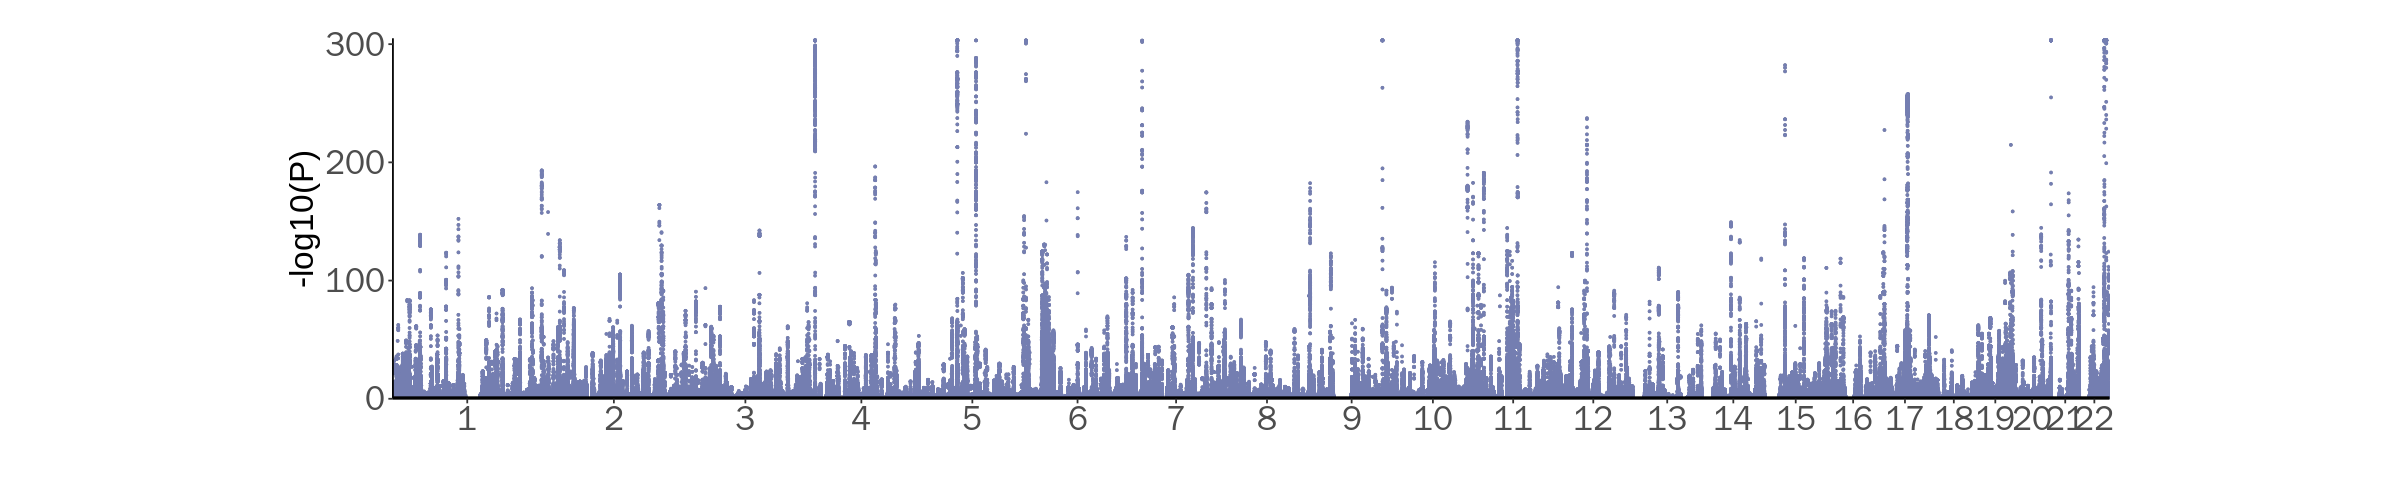

In [4]:
p=gg.manhattan(re1, 0,0.05,0.01, NA, c('grey30','grey60'),c(0,305), '','#747EB1')
print(p)

In [5]:
ct = 'CD8T'
df =data.frame(fread(paste0(ct,'_eqtl_meta_results.csv')))
chr=df$chr
pos=df$pos
SNP=as.character(df$rsID)
P=df$fdr
new=as.data.frame(cbind(chr,as.character(pos),P,as.character(SNP)))
colnames(new)=c('chr','pos','P','SNP')
new$chr <- as.numeric(as.character(new$chr))
new$pos <- as.numeric(as.character(new$pos))
new$P <- as.numeric(as.character(new$P))
new$SNP <- as.character(new$SNP)

min_fdr <- min(new$P[new$P > 0], na.rm = TRUE)
new$P[new$P == 0] <- min_fdr
re2 = new

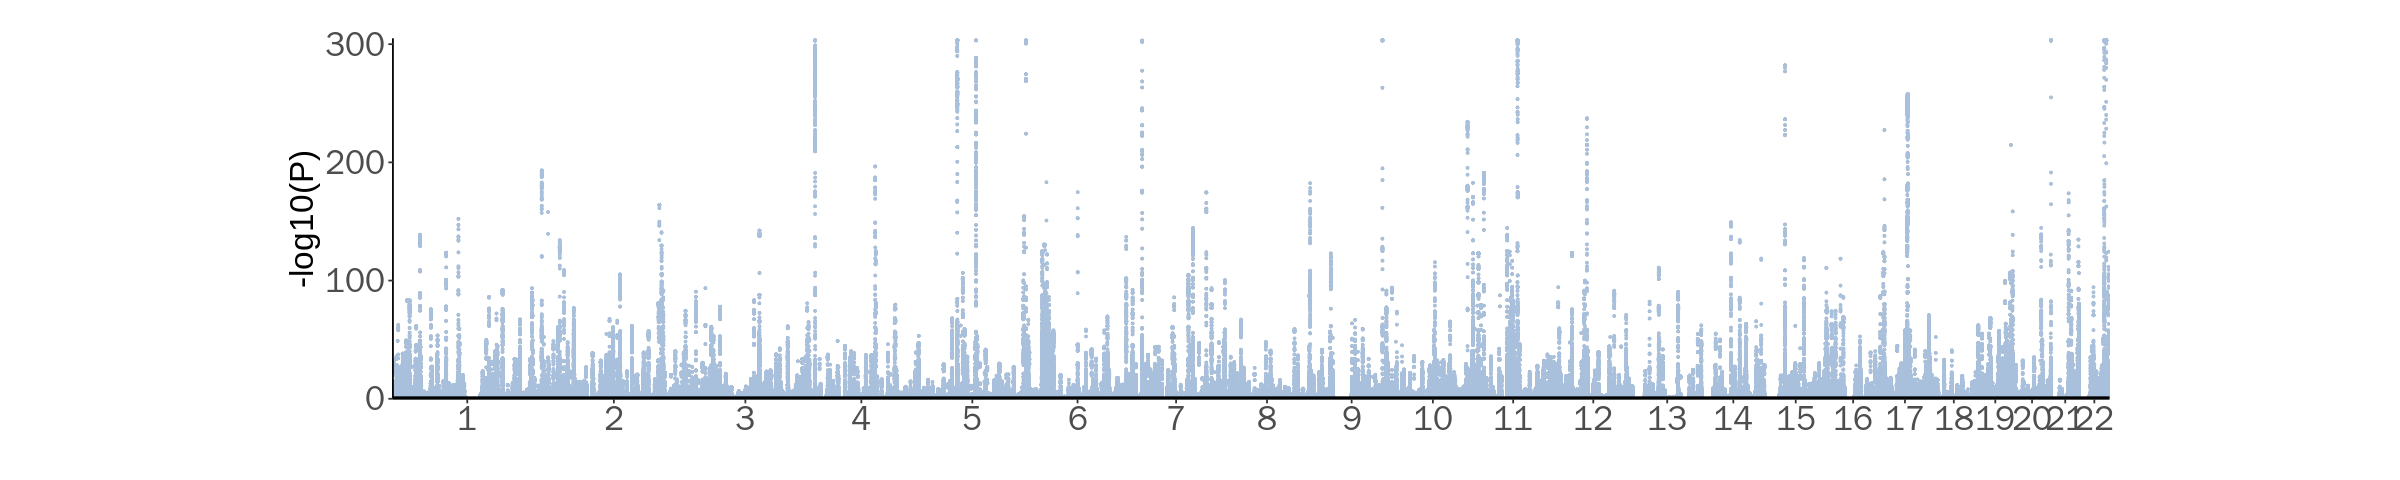

In [6]:
p2=gg.manhattan(re2, 0,0.05,0.01, NA, c('grey30','grey60'),c(0,305), '','#A8C0DC')
print(p2)

# Risk eGene summary

In [7]:
library(RCircos)
library(data.table)
library(dplyr)

Warning message:
“程辑包‘RCircos’是用R版本4.1.3 来建造的”


In [8]:
ref <- fread('../snp_ref/dbsnp_5cols_hg38.tsv')

In [9]:
colnames(ref)[1:3] = c('chr','pos','rsID')

In [14]:
ct = 'CD4T'
meta2 = data.frame(fread(paste0(ct,'_eqtl_meta_results_GWASrisk.csv')))
meta2 = left_join(meta2,ref[,c('chr','pos','rsID')],by = 'rsID')
# eSNP in eQTL
meta2$logP = -log10(meta2$fdr)
test = meta2[!duplicated(meta2$rsID),][c('chr','pos','logP')]
test$stop = test$pos+1
test[test$logP == 'Inf','logP'] = max(test[test$logP != 'Inf',]$logP)
colnames(test) <- c('chromosome','start','logP','stop')
test = test[c('chromosome','start','stop','logP')]

In [15]:
# GWAS SNP annotation
ma2 = data.frame(fread('NG_2021_JT.ma'))
ma2$chromEnd = ma2$base_pair_location+1
ma2$heat = 0 
ma2[ma2$p_value < 5e-8 & ma2$beta >0 ,'heat'] = 1
heat_df = ma2[c('chromosome','base_pair_location','chromEnd','heat')]
colnames(heat_df) <- c('Chromosome', 'chromStart', 'chromEnd','heat')
heat_df$Chromosome = paste0('chr',heat_df$Chromosome)
heat_df$logP = -log10(ma2$p_value)
heat_df[heat_df$logP =='Inf','logP'] = max(heat_df[heat_df$logP != 'Inf',]$logP)


RCircos.Core.Components initialized.
Type ?RCircos.Reset.Plot.Parameters to see how to modify the core components.





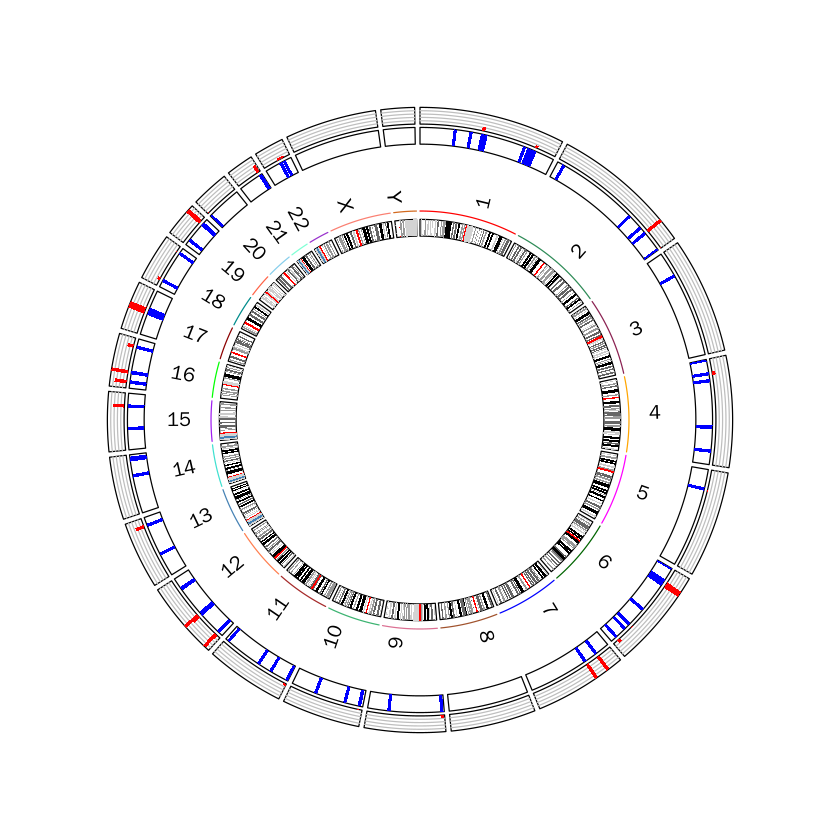

In [16]:
options(repr.plot.width = 7, repr.plot.height = 7)
data(UCSC.HG38.Human.CytoBandIdeogram)
cyto.info <- UCSC.HG38.Human.CytoBandIdeogram
RCircos.Set.Core.Components(cyto.info, #chr.exclude=c('chrX','chrY'),
                            tracks.inside=2, tracks.outside=2)

RCircos.Set.Plot.Area()
RCircos.Chromosome.Ideogram.Plot()

rp = RCircos.Get.Plot.Parameters()
rp$track.height = 0.1
rp$track.background = 'white'
rp$point.size = 3
RCircos.Reset.Plot.Parameters(rp)

data.col <- 4;
track.num <- 1;
side <- "out";
RCircos.Heatmap.Plot(heat_df, data.col, track.num, side);

data.col = 4
track.num= 2
side = 'out'
by.fold = -log10(0.05)

RCircos.Histogram.Plot(test, data.col,track.num, side, by.fold,max.value=10)



RCircos.Core.Components initialized.
Type ?RCircos.Reset.Plot.Parameters to see how to modify the core components.





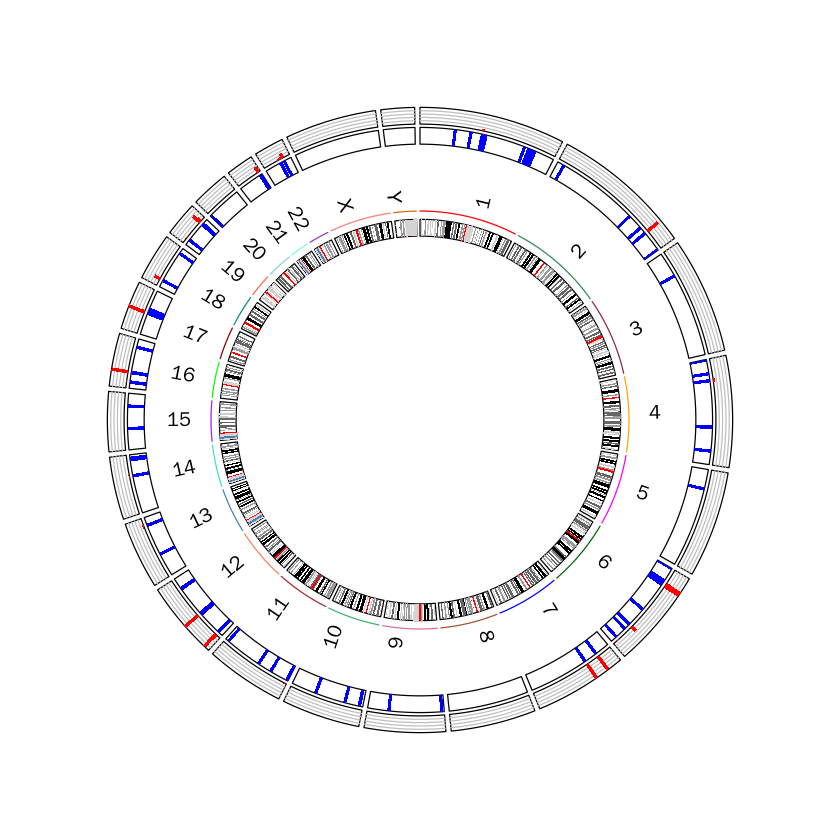

In [17]:
ct = 'CD8T'
meta2 = data.frame(fread(paste0(ct,'_eqtl_meta_results_GWASrisk.csv')))
meta2 = left_join(meta2,ref[,c('chr','pos','rsID')],by = 'rsID')
# eSNP in eQTL
meta2$logP = -log10(meta2$fdr)
test = meta2[!duplicated(meta2$rsID),][c('chr','pos','logP')]
test$stop = test$pos+1
test[test$logP == 'Inf','logP'] = max(test[test$logP != 'Inf',]$logP)
colnames(test) <- c('chromosome','start','logP','stop')
test = test[c('chromosome','start','stop','logP')]

data(UCSC.HG38.Human.CytoBandIdeogram)
cyto.info <- UCSC.HG38.Human.CytoBandIdeogram
RCircos.Set.Core.Components(cyto.info, #chr.exclude=c('chrX','chrY'),
                            tracks.inside=2, tracks.outside=2)

RCircos.Set.Plot.Area()
RCircos.Chromosome.Ideogram.Plot()

rp = RCircos.Get.Plot.Parameters()
rp$track.height = 0.1
rp$track.background = 'white'
rp$point.size = 3
RCircos.Reset.Plot.Parameters(rp)

data.col <- 4;
track.num <- 1;
side <- "out";
RCircos.Heatmap.Plot(heat_df, data.col, track.num, side);

data.col = 4
track.num= 2
side = 'out'
by.fold = -log10(0.05)

RCircos.Histogram.Plot(test, data.col,track.num, side, by.fold,max.value=10)